# 06 — Hyperparameter Tuning (v3, separate models)
LightGBM và XGBoost được tuning, huấn luyện và đánh giá ở các cell độc lập. Feature set và metric lấy từ NB05. Tuning trên 70% development train bằng Stratified 5-Fold; validation 15% dùng để chọn model/weight; không dùng holdout.

**GPU:** XGBoost mặc định CUDA (`cuda:0`, XGBoost >= 2.0); LightGBM chạy CPU. Có thể đổi `XGB_DEVICE = "cpu"` trước khi chạy phần XGBoost. Không tự động chuyển CPU khi GPU không khả dụng. AP là Average Precision; `aucpr` của XGBoost là proxy cho early stopping.

## 1. Setup & Configuration

In [1]:
from pathlib import Path
import sys, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src").is_dir(), "Run from project root or notebooks/"
sys.path.insert(0, str(PROJECT_ROOT))
from src.features import add_features, FEATURE_VERSION, FEATURE_SETS, CATEGORICAL_COLUMNS
from src.config import PRIMARY_METRIC as PRIMARY_METRIC_KEY, SECONDARY_METRIC as SECONDARY_METRIC_KEY, METRIC_LABELS, OUTPUT_VERSION
from src.split import time_based_split, create_stratified_kfold
assert FEATURE_VERSION == "v3", "Copy features_v3.py to src/features.py and restart kernel"
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = DATA_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
N_SPLITS = 5
N_JOBS = 4
# XGBoost uses GPU by default; change to "cpu" explicitly if needed.
XGB_DEVICE = "cuda:0"
import optuna
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

In [2]:
# Total trial targets. Re-running resumes up to these totals; it does not add 30 each time.
TARGET_TRIALS_LGB = 30
TARGET_TRIALS_XGB = 30
MAX_ESTIMATORS_LGB = 4000
MAX_ESTIMATORS_XGB = 4000
EARLY_STOPPING_LGB = 150
EARLY_STOPPING_XGB = 150
MIN_ENSEMBLE_GAIN = 0.001

# Separate persistent checkpoints. Increment revision only after changing a search space.
OPTUNA_STUDY_REVISION = "r1"
LGB_OPTUNA_DB_PATH = (ARTIFACT_DIR / f"06_optuna_lightgbm_{OUTPUT_VERSION}.sqlite3").resolve()
XGB_OPTUNA_DB_PATH = (ARTIFACT_DIR / f"06_optuna_xgboost_{OUTPUT_VERSION}.sqlite3").resolve()


def make_optuna_storage(database_path):
    storage_url = f"sqlite:///{Path(database_path).as_posix()}"
    return optuna.storages.RDBStorage(
        url=storage_url, engine_kwargs={"connect_args": {"timeout": 60}},
        heartbeat_interval=60, grace_period=300)


LGB_OPTUNA_STORAGE = make_optuna_storage(LGB_OPTUNA_DB_PATH)
XGB_OPTUNA_STORAGE = make_optuna_storage(XGB_OPTUNA_DB_PATH)


def save_study_checkpoint(study, csv_path):
    csv_path = Path(csv_path)
    temporary = csv_path.with_suffix(csv_path.suffix + ".tmp")
    study.trials_dataframe().to_csv(temporary, index=False)
    temporary.replace(csv_path)


def optimize_to_target(study, objective, target_trials, csv_path):
    countable = (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)
    finished = sum(trial.state in countable for trial in study.trials)
    failed = sum(trial.state == optuna.trial.TrialState.FAIL for trial in study.trials)
    remaining = max(0, int(target_trials) - finished)
    print(f"Study {study.study_name}: {finished} complete/pruned, {failed} failed, "
          f"{remaining} remaining, target={target_trials}")
    if remaining:
        callback = lambda current_study, _: save_study_checkpoint(current_study, csv_path)
        study.optimize(objective, n_trials=remaining, callbacks=[callback],
                       show_progress_bar=True, gc_after_trial=True)
    else:
        print("Target already reached; no new trial was started.")
    save_study_checkpoint(study, csv_path)

## 2. Data Preparation & Cross-Validation

In [3]:
def load_featured(kind):
    raw_path = DATA_DIR / f"{kind}.csv"
    cache_path = DATA_DIR / f"{kind}_featured_{FEATURE_VERSION}.pkl"
    required = set(FEATURE_SETS["compact_all"]) | {"id"}
    identity_cols = ["id", "is_fraud"] if kind == "train" else ["id"]
    required.update(identity_cols)
    if cache_path.exists() and cache_path.stat().st_mtime >= raw_path.stat().st_mtime:
        try:
            frame = pd.read_pickle(cache_path)
            identity = pd.read_csv(raw_path, usecols=identity_cols)
            if not required.issubset(frame.columns):
                raise ValueError("Missing v3 features")
            for col in identity_cols:
                if not np.array_equal(frame[col].to_numpy(), identity[col].to_numpy()):
                    raise ValueError(f"Cached {col} alignment mismatch")
            if not frame["id"].is_unique:
                raise ValueError("Duplicate IDs")
            print("Loaded:", cache_path.name)
            return frame.reset_index(drop=True)
        except (OSError, ImportError, AttributeError, TypeError, ValueError,
                NotImplementedError, EOFError, pickle.UnpicklingError) as exc:
            print(f"Rebuilding {cache_path.name}: {exc}")
    raw = pd.read_csv(raw_path)
    frame = add_features(raw.drop(columns="is_fraud", errors="ignore"))
    if kind == "train":
        frame["is_fraud"] = raw["is_fraud"].astype(int)
    assert frame["id"].is_unique and required.issubset(frame.columns)
    frame.to_pickle(cache_path)
    print("Saved:", cache_path.name)
    return frame.reset_index(drop=True)


def align_categories(train, *others, cat_cols):
    train = train.copy()
    others = [frame.copy() for frame in others]
    for col in cat_cols:
        # Materialize strings to ensure XGBoost-compatible categorical labels.
        train[col] = train[col].astype(object).astype("category").cat.remove_unused_categories()
        cats = train[col].cat.categories
        for frame in others:
            frame[col] = pd.Categorical(frame[col].astype(object), categories=cats)
    return (train, *others)


def split_development(frame):
    parts = time_based_split(frame, id_col="id", train_ratio=0.70,
                             valid_ratio=0.15, buffer_size=0)
    return tuple(parts[k].sort_values("id").reset_index(drop=True)
                 for k in ("train", "valid", "test_holdout"))


def scores(y, p):
    return {"AP": float(average_precision_score(y, p)),
            "ROC-AUC": float(roc_auc_score(y, p)),
            "Brier": float(brier_score_loss(y, p))}

In [4]:
selection = json.loads((ARTIFACT_DIR / f"05_feature_selection_{OUTPUT_VERSION}.json").read_text(encoding="utf-8"))
assert selection["feature_version"] == FEATURE_VERSION
ACTIVE_FEATURE_SET = selection["feature_set"]
FEATURE_COLS = list(FEATURE_SETS[ACTIVE_FEATURE_SET])
assert FEATURE_COLS == selection["feature_columns"]
assert selection["random_state"] == RANDOM_STATE and selection["n_splits"] == N_SPLITS
assert selection["allow_ai_flag"] or "is_ai_generated_scam_attempt" not in FEATURE_COLS
CAT_COLS = [c for c in FEATURE_COLS if c in CATEGORICAL_COLUMNS]
PRIMARY_METRIC = METRIC_LABELS[PRIMARY_METRIC_KEY]
SECONDARY_METRIC = METRIC_LABELS[SECONDARY_METRIC_KEY]
assert selection["primary_metric"] == PRIMARY_METRIC == "ROC-AUC"
assert selection["secondary_metric"] == SECONDARY_METRIC == "AP"
metric_fn = roc_auc_score
lgb_metric = "auc"
xgb_metric = "auc"
all_df = load_featured("train")
train_df, valid_df, holdout_df = split_development(all_df)
assert len(train_df) == selection["development_rows"]
y_train, y_valid = [d.is_fraud.to_numpy(dtype=int) for d in (train_df, valid_df)]
X_train, X_valid = align_categories(train_df[FEATURE_COLS], valid_df[FEATURE_COLS], cat_cols=CAT_COLS)
cv_splits = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train))
# Verify IDs and folds match NB05 rather than solely comparing row counts.
with np.load(ARTIFACT_DIR / f"05_oof_{OUTPUT_VERSION}.npz", allow_pickle=False) as previous:
    assert np.array_equal(previous["ids"], train_df.id.astype(str).to_numpy(dtype=str))
    assert np.array_equal(previous["y"], y_train)
    for fold, (_, va) in enumerate(cv_splits):
        assert (previous["folds"][va] == fold).all()
print(ACTIVE_FEATURE_SET, len(FEATURE_COLS), PRIMARY_METRIC)

Loaded: train_featured_v3.pkl
raw_core 23 ROC-AUC


In [5]:
n_neg, n_pos = int((y_train == 0).sum()), int((y_train == 1).sum())
print(f"Non-fraud: {n_neg:,} | Fraud: {n_pos:,} | Rate: {y_train.mean():.4%}")
print(f"Train: {len(train_df):,} | Validation: {len(valid_df):,} | Holdout (unused): {len(holdout_df):,}")
print(f"Metric: {PRIMARY_METRIC} | Features: {len(FEATURE_COLS)} | Categorical: {len(CAT_COLS)}")
display(pd.DataFrame([{"fold": i, "train_rows": len(tr), "valid_rows": len(va),
                       "valid_fraud_rate": y_train[va].mean()} for i, (tr, va) in enumerate(cv_splits)]))

Non-fraud: 481,729 | Fraud: 8,242 | Rate: 1.6821%
Train: 489,971 | Validation: 104,995 | Holdout (unused): 104,994
Metric: ROC-AUC | Features: 23 | Categorical: 5


,fold,train_rows,valid_rows,valid_fraud_rate
0,0,391976,97995,0.016827
1,1,391977,97994,0.016817
2,2,391977,97994,0.016817
3,3,391977,97994,0.016817
4,4,391977,97994,0.016828


## 3. LightGBM — Hyperparameter Tuning
Chạy các cell bên dưới độc lập với phần XGBoost. CPU, native categorical support và early stopping trong mỗi fold.

In [6]:
def base_lgb_params():
    return dict(objective="binary", random_state=RANDOM_STATE, n_jobs=N_JOBS,
                verbosity=-1, subsample_freq=1, metric=lgb_metric, device_type="cpu")


def objective_lgb(trial):
    depth = trial.suggest_int("max_depth", 2, 6)
    params = {**base_lgb_params(),
        "n_estimators": MAX_ESTIMATORS_LGB,
        "max_depth": depth,
        "num_leaves": trial.suggest_int("num_leaves", 3, min(63, 2**depth)),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 200),
        "learning_rate": trial.suggest_float("learning_rate", .005, .08, log=True),
        "subsample": trial.suggest_float("subsample", .6, 1.),
        "colsample_bytree": trial.suggest_float("colsample_bytree", .6, 1.),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-5, 10., log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-5, 20., log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1., 5., log=True)}
    fold_roc_auc, fold_ap, best_iterations = [], [], []
    for fold, (tr, va) in enumerate(cv_splits):
        X_tr, X_va = align_categories(X_train.iloc[tr], X_train.iloc[va], cat_cols=CAT_COLS)
        model = lgb.LGBMClassifier(**params)
        model.fit(X_tr, y_train[tr], eval_set=[(X_va, y_train[va])],
                  callbacks=[lgb.early_stopping(EARLY_STOPPING_LGB, first_metric_only=True, verbose=False),
                             lgb.log_evaluation(period=0)])
        best_iterations.append(int(model.best_iteration_))
        fold_prob = model.predict_proba(X_va)[:, 1]
        fold_roc_auc.append(float(roc_auc_score(y_train[va], fold_prob)))
        fold_ap.append(float(average_precision_score(y_train[va], fold_prob)))
        trial.report(float(np.mean(fold_roc_auc)), step=fold)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("fold_roc_auc", fold_roc_auc)
    trial.set_user_attr("fold_average_precision", fold_ap)
    trial.set_user_attr("mean_roc_auc", float(np.mean(fold_roc_auc)))
    trial.set_user_attr("mean_average_precision", float(np.mean(fold_ap)))
    trial.set_user_attr("cv_std", float(np.std(fold_roc_auc)))
    trial.set_user_attr("ap_cv_std", float(np.std(fold_ap)))
    trial.set_user_attr("best_iterations", best_iterations)
    return float(np.mean(fold_roc_auc))

In [7]:
lgb_study_name = f"LightGBM_{OUTPUT_VERSION}_{ACTIVE_FEATURE_SET}_{PRIMARY_METRIC_KEY}_{OPTUNA_STUDY_REVISION}"
study_lgb = optuna.create_study(
    study_name=lgb_study_name, storage=LGB_OPTUNA_STORAGE, load_if_exists=True, direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2))
study_lgb.set_user_attr("feature_set", ACTIVE_FEATURE_SET)
study_lgb.set_user_attr("primary_metric", PRIMARY_METRIC_KEY)
study_lgb.set_user_attr("study_revision", OPTUNA_STUDY_REVISION)
optimize_to_target(study_lgb, objective_lgb, TARGET_TRIALS_LGB,
                   ARTIFACT_DIR / f"06_LightGBM_trials_{OUTPUT_VERSION}.csv")

[I 2026-11-24 00:22:52,693] A new study created in memory with name: LightGBM_v3_ROC-AUC


  0%|          | 0/30 [00:00<?, ?it/s]

d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set

[I 2026-11-24 00:25:03,335] Trial 0 finished with value: 0.9454400890947442 and parameters: {'max_depth': 3, 'num_leaves': 8, 'min_child_samples': 152, 'learning_rate': 0.026292183092620925, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 2.231010801867923e-05, 'reg_lambda': 2.8694712385318164, 'scale_pos_weight': 2.631245451057451}. Best is trial 0 with value: 0.9454400890947442.


d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set

[I 2026-11-24 00:27:22,616] Trial 1 finished with value: 0.9456028890993501 and parameters: {'max_depth': 5, 'num_leaves': 3, 'min_child_samples': 195, 'learning_rate': 0.05027253932873333, 'subsample': 0.6849356442713105, 'colsample_bytree': 0.6727299868828402, 'reg_alpha': 0.00012601639723276795, 'reg_lambda': 0.0008261130806754192, 'scale_pos_weight': 2.326960468194962}. Best is trial 1 with value: 0.9456028890993501.


... (52 outputs left out)

d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set

[I 2026-11-24 08:13:05,783] Trial 28 finished with value: 0.9455527474230564 and parameters: {'max_depth': 3, 'num_leaves': 4, 'min_child_samples': 200, 'learning_rate': 0.03141487791412837, 'subsample': 0.8172198268059172, 'colsample_bytree': 0.6427551274106433, 'reg_alpha': 3.512797347228653e-05, 'reg_lambda': 1.0866330361696364e-05, 'scale_pos_weight': 1.8597203680982433}. Best is trial 22 with value: 0.9457069790514883.


d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set

[I 2026-11-24 08:14:40,899] Trial 29 finished with value: 0.9454141496498331 and parameters: {'max_depth': 2, 'num_leaves': 3, 'min_child_samples': 141, 'learning_rate': 0.07495674708801889, 'subsample': 0.8801830987551812, 'colsample_bytree': 0.6007400256712535, 'reg_alpha': 1.1453205648766882e-05, 'reg_lambda': 0.00018566908784936265, 'scale_pos_weight': 2.6275474619740997}. Best is trial 22 with value: 0.9457069790514883.


### LightGBM — Optuna results & visualization

Best trial: 22 | Mean CV ROC-AUC: 0.945707
CV Std: 0.001817
Best iterations per fold: [2566, 2195, 2046, 2216, 2033]


,Parameter,Value
0,max_depth,2.000000
1,num_leaves,3.000000
2,min_child_samples,200.000000
3,learning_rate,0.044095
4,subsample,0.873668
5,colsample_bytree,0.646664
6,reg_alpha,0.000096
7,reg_lambda,0.000011
8,scale_pos_weight,1.840311


C:\Users\Admin\AppData\Local\Temp\ipykernel_14072\1335827434.py:5: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study_lgb); plt.title("LightGBM Optimization History"); plt.tight_layout(); plt.show()


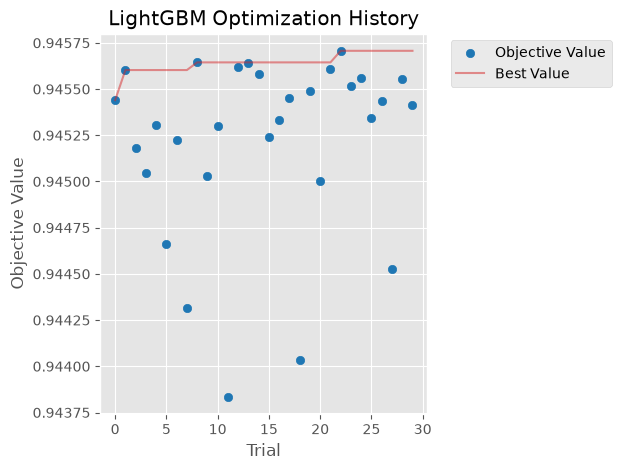

C:\Users\Admin\AppData\Local\Temp\ipykernel_14072\1335827434.py:8: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study_lgb); plt.title("LightGBM Hyperparameter Importance"); plt.tight_layout(); plt.show()


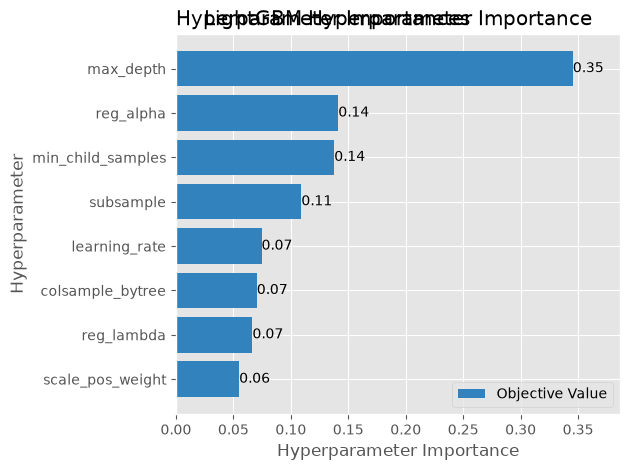

In [8]:
print(f"Best trial: {study_lgb.best_trial.number} | Mean CV {PRIMARY_METRIC}: {study_lgb.best_value:.6f}")
print(f"CV Std: {study_lgb.best_trial.user_attrs['cv_std']:.6f}")
print("Best iterations per fold:", study_lgb.best_trial.user_attrs["best_iterations"])
display(pd.DataFrame(study_lgb.best_params.items(), columns=["Parameter", "Value"]))
plot_optimization_history(study_lgb); plt.title("LightGBM Optimization History"); plt.tight_layout(); plt.show()
completed = study_lgb.get_trials(states=(optuna.trial.TrialState.COMPLETE,))
if len(completed) >= 2 and len({t.value for t in completed}) >= 2:
    plot_param_importances(study_lgb); plt.title("LightGBM Hyperparameter Importance"); plt.tight_layout(); plt.show()
else:
    print("Not enough distinct completed trials for parameter importance.")

### LightGBM — Final training & validation

In [25]:
best_lgb_n_estimators = max(1, int(np.median(study_lgb.best_trial.user_attrs["best_iterations"])))
best_lgb_params = {**base_lgb_params(), **study_lgb.best_params,
                     "n_estimators": best_lgb_n_estimators}
# Fixed number of trees; no early stopping/eval_set in final refit.
display(pd.DataFrame(best_lgb_params.items(), columns=["Parameter", "Value"]))
(ARTIFACT_DIR / f"06_LightGBM_best_params_{OUTPUT_VERSION}.json").write_text(
    json.dumps(best_lgb_params, indent=2), encoding="utf-8")

,Parameter,Value
0,objective,binary
1,random_state,42
2,n_jobs,4
3,verbosity,-1
4,subsample_freq,1
5,metric,auc
6,device_type,cpu
7,max_depth,2
8,num_leaves,3
9,min_child_samples,200


474

In [10]:
lgb_tuned = lgb.LGBMClassifier(**best_lgb_params)
lgb_tuned.fit(X_train, y_train)
print("LightGBM final training completed.")

LightGBM final training completed.


In [26]:
lgb_train_probs = lgb_tuned.predict_proba(X_train)[:, 1]
lgb_valid_probs = lgb_tuned.predict_proba(X_valid)[:, 1]
lgb_tuned_results = {"model": "LightGBM", **scores(y_valid, lgb_valid_probs),
    "Train AP": float(average_precision_score(y_train, lgb_train_probs)),
    "Train ROC-AUC": float(roc_auc_score(y_train, lgb_train_probs)),
    "CV mean": study_lgb.best_value, "CV std": study_lgb.best_trial.user_attrs["cv_std"]}
display(pd.DataFrame([lgb_tuned_results]))

,model,AP,ROC-AUC,Brier,Train AP,Train ROC-AUC,CV mean,CV std
0,LightGBM,0.495415,0.942342,0.011515,0.524947,0.9501,0.945707,0.001817


## 4. XGBoost — Hyperparameter Tuning (GPU)
Phần này không phụ thuộc vào `study_lgb` hay `lgb_tuned`. GPU probe chạy trước Optuna để tránh việc mất thời gian tuning nếu XGBoost tự fallback về CPU. Nếu thay `XGB_DEVICE` sau khi chạy setup, chạy lại probe trước khi tuning.

In [12]:
def verify_xgb_device():
    if XGB_DEVICE == "cpu":
        print("XGBoost: CPU mode (explicit choice)")
        return
    if not XGB_DEVICE.startswith("cuda"):
        raise ValueError("Set XGB_DEVICE to 'cuda:0' or 'cpu'.")
    if int(xgb.__version__.split(".")[0]) < 2:
        raise RuntimeError("GPU configuration needs xgboost >= 2.0.")
    probe = xgb.XGBClassifier(n_estimators=1, max_depth=1, tree_method="hist",
                              device=XGB_DEVICE, n_jobs=1, verbosity=1)
    try:
        data = np.arange(64, dtype=np.float32).reshape(-1, 2)
        probe.fit(data, np.tile([0, 1], 16))
        actual_device = json.loads(probe.get_booster().save_config())["learner"]["generic_param"]["device"]
    except Exception as exc:
        raise RuntimeError("GPU probe failed. Check NVIDIA driver and CUDA-enabled XGBoost, or explicitly set XGB_DEVICE='cpu'.") from exc
    if not actual_device.startswith("cuda"):
        raise RuntimeError(f"Requested {XGB_DEVICE}, but XGBoost uses {actual_device}. Check GPU setup or set XGB_DEVICE='cpu'.")
    print(f"XGBoost {xgb.__version__} | GPU verified: {actual_device}")

In [13]:
def base_xgb_params():
    return dict(objective="binary:logistic", tree_method="hist", device=XGB_DEVICE,
                enable_categorical=True, eval_metric=xgb_metric,
                random_state=RANDOM_STATE, n_jobs=N_JOBS, verbosity=0)


def objective_xgb(trial):
    params = {**base_xgb_params(),
        "n_estimators": MAX_ESTIMATORS_XGB,
        "early_stopping_rounds": EARLY_STOPPING_XGB,
        "max_depth": trial.suggest_int("max_depth", 1, 6),
        "min_child_weight": trial.suggest_float("min_child_weight", 1., 50., log=True),
        "gamma": trial.suggest_float("gamma", 0., 5.),
        "learning_rate": trial.suggest_float("learning_rate", .005, .08, log=True),
        "subsample": trial.suggest_float("subsample", .6, 1.),
        "colsample_bytree": trial.suggest_float("colsample_bytree", .6, 1.),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-5, 10., log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-5, 20., log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1., 5., log=True)}
    fold_roc_auc, fold_ap, best_iterations = [], [], []
    for fold, (tr, va) in enumerate(cv_splits):
        X_tr, X_va = align_categories(X_train.iloc[tr], X_train.iloc[va], cat_cols=CAT_COLS)
        model = xgb.XGBClassifier(**params)
        model.fit(X_tr, y_train[tr], eval_set=[(X_va, y_train[va])], verbose=False)
        best_iterations.append(int(model.best_iteration + 1))
        fold_prob = model.predict_proba(X_va)[:, 1]
        fold_roc_auc.append(float(roc_auc_score(y_train[va], fold_prob)))
        fold_ap.append(float(average_precision_score(y_train[va], fold_prob)))
        trial.report(float(np.mean(fold_roc_auc)), step=fold)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("fold_roc_auc", fold_roc_auc)
    trial.set_user_attr("fold_average_precision", fold_ap)
    trial.set_user_attr("mean_roc_auc", float(np.mean(fold_roc_auc)))
    trial.set_user_attr("mean_average_precision", float(np.mean(fold_ap)))
    trial.set_user_attr("cv_std", float(np.std(fold_roc_auc)))
    trial.set_user_attr("ap_cv_std", float(np.std(fold_ap)))
    trial.set_user_attr("best_iterations", best_iterations)
    return float(np.mean(fold_roc_auc))

In [14]:
verify_xgb_device()
xgb_study_name = f"XGBoost_{OUTPUT_VERSION}_{ACTIVE_FEATURE_SET}_{PRIMARY_METRIC_KEY}_{OPTUNA_STUDY_REVISION}"
study_xgb = optuna.create_study(
    study_name=xgb_study_name, storage=XGB_OPTUNA_STORAGE, load_if_exists=True, direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2))
study_xgb.set_user_attr("feature_set", ACTIVE_FEATURE_SET)
study_xgb.set_user_attr("primary_metric", PRIMARY_METRIC_KEY)
study_xgb.set_user_attr("study_revision", OPTUNA_STUDY_REVISION)
optimize_to_target(study_xgb, objective_xgb, TARGET_TRIALS_XGB,
                   ARTIFACT_DIR / f"06_XGBoost_trials_{OUTPUT_VERSION}.csv")

[I 2026-11-24 08:15:09,866] A new study created in memory with name: XGBoost_v3_ROC-AUC


XGBoost 3.4.1 | GPU verified: cuda:0


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-24 08:15:37,451] Trial 0 finished with value: 0.9450290748519258 and parameters: {'max_depth': 3, 'min_child_weight': 41.23206532618726, 'gamma': 3.6599697090570253, 'learning_rate': 0.026292183092620925, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 2.231010801867923e-05, 'reg_lambda': 2.8694712385318164, 'scale_pos_weight': 2.631245451057451}. Best is trial 0 with value: 0.9450290748519258.
[I 2026-11-24 08:15:51,295] Trial 1 finished with value: 0.9441968928364354 and parameters: {'max_depth': 5, 'min_child_weight': 1.0838581269344745, 'gamma': 4.8495492608099715, 'learning_rate': 0.05027253932873333, 'subsample': 0.6849356442713105, 'colsample_bytree': 0.6727299868828402, 'reg_alpha': 0.00012601639723276795, 'reg_lambda': 0.0008261130806754192, 'scale_pos_weight': 2.326960468194962}. Best is trial 0 with value: 0.9450290748519258.
[I 2026-11-24 08:16:50,592] Trial 2 finished with value: 0.9449783948919166 and parameters: {'max_depth

### XGBoost — Optuna results & visualization

Best trial: 17 | Mean CV ROC-AUC: 0.945436
CV Std: 0.002000
Best iterations per fold: [3750, 2044, 1617, 2486, 2570]


,Parameter,Value
0,max_depth,2.000000
1,min_child_weight,19.884151
2,gamma,4.381266
3,learning_rate,0.033967
4,subsample,0.770099
5,colsample_bytree,0.825252
6,reg_alpha,0.000059
7,reg_lambda,0.330593
8,scale_pos_weight,1.725539


C:\Users\Admin\AppData\Local\Temp\ipykernel_14072\2872549667.py:5: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study_xgb); plt.title("XGBoost Optimization History"); plt.tight_layout(); plt.show()


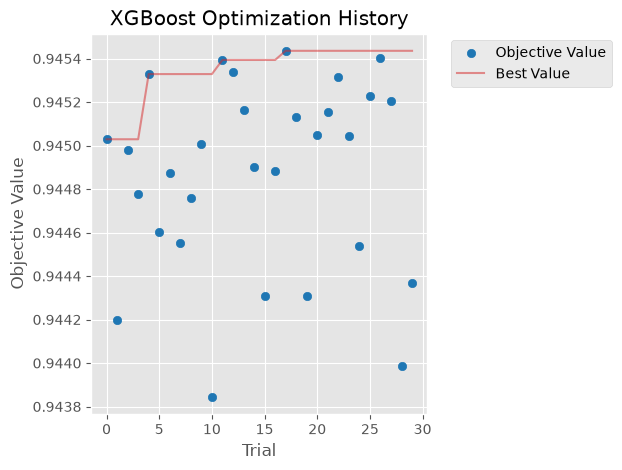

C:\Users\Admin\AppData\Local\Temp\ipykernel_14072\2872549667.py:8: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study_xgb); plt.title("XGBoost Hyperparameter Importance"); plt.tight_layout(); plt.show()


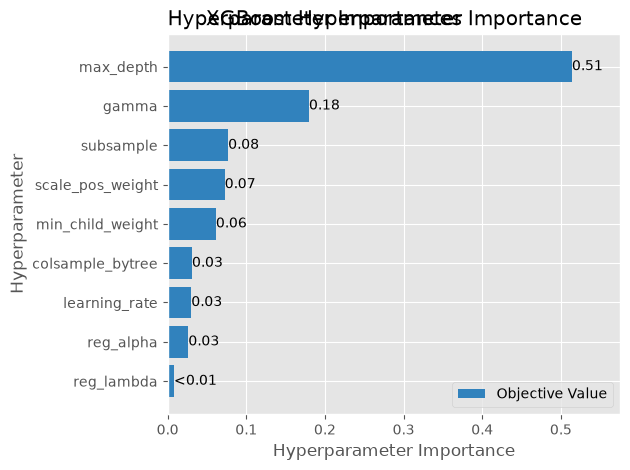

In [27]:
print(f"Best trial: {study_xgb.best_trial.number} | Mean CV {PRIMARY_METRIC}: {study_xgb.best_value:.6f}")
print(f"CV Std: {study_xgb.best_trial.user_attrs['cv_std']:.6f}")
print("Best iterations per fold:", study_xgb.best_trial.user_attrs["best_iterations"])
display(pd.DataFrame(study_xgb.best_params.items(), columns=["Parameter", "Value"]))
plot_optimization_history(study_xgb); plt.title("XGBoost Optimization History"); plt.tight_layout(); plt.show()
completed = study_xgb.get_trials(states=(optuna.trial.TrialState.COMPLETE,))
if len(completed) >= 2 and len({t.value for t in completed}) >= 2:
    plot_param_importances(study_xgb); plt.title("XGBoost Hyperparameter Importance"); plt.tight_layout(); plt.show()
else:
    print("Not enough distinct completed trials for parameter importance.")

### XGBoost — Final training & validation

In [28]:
best_xgb_n_estimators = max(1, int(np.median(study_xgb.best_trial.user_attrs["best_iterations"])))
best_xgb_params = {**base_xgb_params(), **study_xgb.best_params,
                     "n_estimators": best_xgb_n_estimators}
# Fixed number of trees; no early stopping/eval_set in final refit.
display(pd.DataFrame(best_xgb_params.items(), columns=["Parameter", "Value"]))
(ARTIFACT_DIR / f"06_XGBoost_best_params_{OUTPUT_VERSION}.json").write_text(
    json.dumps(best_xgb_params, indent=2), encoding="utf-8")

,Parameter,Value
0,objective,binary:logistic
1,tree_method,hist
2,device,cuda:0
3,enable_categorical,True
4,eval_metric,auc
5,random_state,42
6,n_jobs,4
7,verbosity,0
8,max_depth,2
9,min_child_weight,19.884151


536

In [29]:
xgb_tuned = xgb.XGBClassifier(**best_xgb_params)
xgb_tuned.fit(X_train, y_train)
print("XGBoost final training completed.")

XGBoost final training completed.


In [30]:
xgb_train_probs = xgb_tuned.predict_proba(X_train)[:, 1]
xgb_valid_probs = xgb_tuned.predict_proba(X_valid)[:, 1]
xgb_tuned_results = {"model": "XGBoost", **scores(y_valid, xgb_valid_probs),
    "Train AP": float(average_precision_score(y_train, xgb_train_probs)),
    "Train ROC-AUC": float(roc_auc_score(y_train, xgb_train_probs)),
    "CV mean": study_xgb.best_value, "CV std": study_xgb.best_trial.user_attrs["cv_std"]}
display(pd.DataFrame([xgb_tuned_results]))

,model,AP,ROC-AUC,Brier,Train AP,Train ROC-AUC,CV mean,CV std
0,XGBoost,0.493837,0.942333,0.011454,0.528426,0.950564,0.945436,0.002


## 5. Model Comparison
Chỉ phần này và các phần sau cần kết quả của cả hai model.

In [31]:
tuned_params = {"LightGBM": best_lgb_params, "XGBoost": best_xgb_params}
valid_predictions = {"LightGBM": lgb_valid_probs, "XGBoost": xgb_valid_probs}
comparison = [lgb_tuned_results.copy(), xgb_tuned_results.copy()]
display(pd.DataFrame(comparison).sort_values(PRIMARY_METRIC, ascending=False))
prediction_df = pd.DataFrame(valid_predictions)
print(f"Pearson correlation: {prediction_df.corr(method='pearson').iloc[0, 1]:.6f}")
print(f"Spearman correlation: {prediction_df.corr(method='spearman').iloc[0, 1]:.6f}")

# Generate pooled OOF predictions with tuned fixed-iteration models.
oof_predictions = {name: np.full(len(y_train), np.nan) for name in tuned_params}
for fold, (tr, va) in enumerate(cv_splits):
    X_tr, X_va = align_categories(X_train.iloc[tr], X_train.iloc[va], cat_cols=CAT_COLS)
    for name in ("LightGBM", "XGBoost"):
        model_cls = lgb.LGBMClassifier if name == "LightGBM" else xgb.XGBClassifier
        model = model_cls(**tuned_params[name]).fit(X_tr, y_train[tr])
        oof_predictions[name][va] = model.predict_proba(X_va)[:, 1]
    print(f"OOF fold {fold}:", {name: scores(y_train[va], p[va]) for name, p in oof_predictions.items()})
assert all(np.isfinite(p).all() for p in oof_predictions.values())
oof_model_comparison = pd.DataFrame([
    {"model": name, **scores(y_train, p)} for name, p in oof_predictions.items()])
display(oof_model_comparison.sort_values(PRIMARY_METRIC, ascending=False))

,model,AP,ROC-AUC,Brier,Train AP,Train ROC-AUC,CV mean,CV std
0,LightGBM,0.495415,0.942342,0.011515,0.524947,0.950100,0.945707,0.001817
1,XGBoost,0.493837,0.942333,0.011454,0.528426,0.950564,0.945436,0.002000


Pearson correlation: 0.995795
Spearman correlation: 0.995359
OOF fold 0: {'LightGBM': {'AP': 0.5031291005715955, 'ROC-AUC': 0.9476625564594819, 'Brier': 0.01178617096717495}, 'XGBoost': {'AP': 0.5023938680604969, 'ROC-AUC': 0.9478404924428615, 'Brier': 0.01169442945494793}}
OOF fold 1: {'LightGBM': {'AP': 0.5055692388064172, 'ROC-AUC': 0.9445032784347837, 'Brier': 0.011629004181063437}, 'XGBoost': {'AP': 0.5038375689251228, 'ROC-AUC': 0.9441465260774324, 'Brier': 0.01156258480033799}}
OOF fold 2: {'LightGBM': {'AP': 0.5000586066718119, 'ROC-AUC': 0.9428221913173374, 'Brier': 0.011720358723206105}, 'XGBoost': {'AP': 0.49833708941753607, 'ROC-AUC': 0.9425295157632716, 'Brier': 0.011631494382947104}}
OOF fold 3: {'LightGBM': {'AP': 0.49873591213197943, 'ROC-AUC': 0.9461441963118767, 'Brier': 0.011672215939500658}, 'XGBoost': {'AP': 0.4989994655297662, 'ROC-AUC': 0.9455950151547245, 'Brier': 0.011566916828918103}}
OOF fold 4: {'LightGBM': {'AP': 0.5193403976752784, 'ROC-AUC': 0.94719217225

,model,AP,ROC-AUC,Brier
0,LightGBM,0.505210,0.945663,0.011642
1,XGBoost,0.504798,0.945429,0.011547


## 6. Ensemble Optimization
Tối ưu weight chỉ trên validation; giữ nguyên quy tắc chọn model của v3.

In [32]:
p_lgb_oof, p_xgb_oof = oof_predictions["LightGBM"], oof_predictions["XGBoost"]
ensemble_avg_oof = .5 * p_lgb_oof + .5 * p_xgb_oof
print("50:50 OOF blend:", scores(y_train, ensemble_avg_oof))
blend_df = pd.DataFrame([{"alpha": float(a), **scores(y_train, a*p_lgb_oof + (1-a)*p_xgb_oof)}
                         for a in np.linspace(0, 1, 101)])
best = blend_df.loc[blend_df[PRIMARY_METRIC].idxmax()]
best_alpha = float(best.alpha)
best_blend = float(best[PRIMARY_METRIC])
display(blend_df.sort_values(PRIMARY_METRIC, ascending=False).head(10))

50:50 OOF blend: {'AP': 0.5059081176146668, 'ROC-AUC': 0.945687125436109, 'Brier': 0.011575066696267233}


,alpha,AP,ROC-AUC,Brier
70,0.70,0.505860,0.945709,0.011597
72,0.72,0.505832,0.945709,0.011600
71,0.71,0.505849,0.945709,0.011598
69,0.69,0.505870,0.945709,0.011596
68,0.68,0.505876,0.945709,0.011595
73,0.73,0.505813,0.945709,0.011601
67,0.67,0.505882,0.945708,0.011594
74,0.74,0.505796,0.945708,0.011602
66,0.66,0.505893,0.945708,0.011592
75,0.75,0.505785,0.945708,0.011604


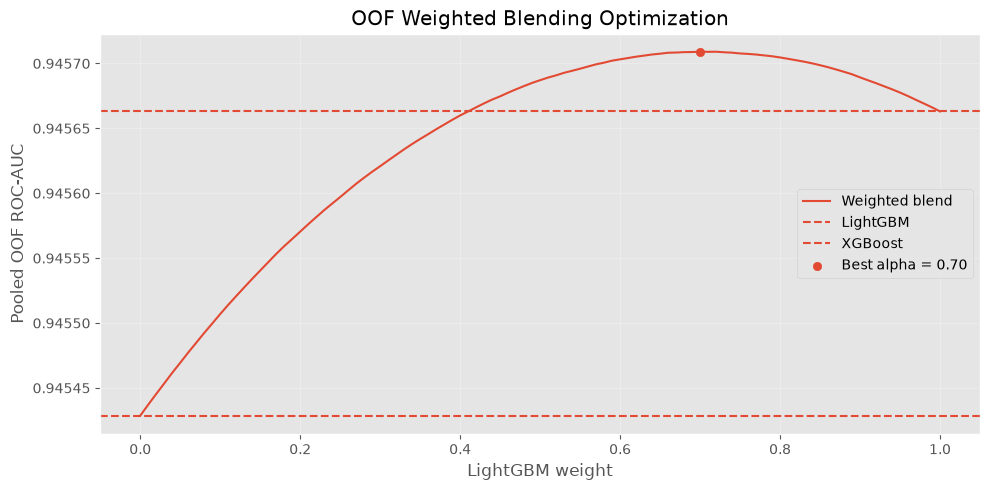

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(blend_df["alpha"], blend_df[PRIMARY_METRIC], label="Weighted blend")
ax.axhline(metric_fn(y_train, p_lgb_oof), linestyle="--", label="LightGBM")
ax.axhline(metric_fn(y_train, p_xgb_oof), linestyle="--", label="XGBoost")
ax.scatter(best_alpha, best_blend, zorder=5, label=f"Best alpha = {best_alpha:.2f}")
ax.set(xlabel="LightGBM weight", ylabel=f"Pooled OOF {PRIMARY_METRIC}", title="OOF Weighted Blending Optimization")
ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

## 7. Final Model Selection

In [34]:
single_name = max(oof_predictions, key=lambda name: metric_fn(y_train, oof_predictions[name]))
single_score = float(metric_fn(y_train, oof_predictions[single_name]))
ensemble_gain = best_blend - single_score
selected_model = "Weighted Blending" if ensemble_gain >= MIN_ENSEMBLE_GAIN else single_name
selected_score = best_blend if selected_model == "Weighted Blending" else single_score
# OOF drives selection; validation remains monitoring only.
p_lgb, p_xgb = lgb_valid_probs, xgb_valid_probs
ensemble_avg_probs = .5 * p_lgb + .5 * p_xgb
final_comparison = pd.DataFrame(comparison + [
    {"model": "Simple Averaging", **scores(y_valid, ensemble_avg_probs)},
    {"model": "Weighted Blending", **scores(y_valid, best_alpha*p_lgb+(1-best_alpha)*p_xgb)}])
oof_comparison = pd.concat([oof_model_comparison, pd.DataFrame([
    {"model": "Simple Averaging", **scores(y_train, ensemble_avg_oof)},
    {"model": "Weighted Blending", **scores(y_train, best_alpha*p_lgb_oof+(1-best_alpha)*p_xgb_oof)}])], ignore_index=True)
print("OOF comparison (used for selection):")
display(oof_comparison.sort_values(PRIMARY_METRIC, ascending=False))
print("Validation comparison (monitoring only):")
display(final_comparison.sort_values(PRIMARY_METRIC, ascending=False))
print(f"Best single: {single_name} | Ensemble gain: {ensemble_gain:+.6f}")
print(f"Selected: {selected_model} | {PRIMARY_METRIC}: {selected_score:.6f}")
print(f"Best blend: LightGBM={best_alpha:.2f}, XGBoost={1-best_alpha:.2f}")

OOF comparison (used for selection):


,model,AP,ROC-AUC,Brier
3,Weighted Blending,0.505860,0.945709,0.011597
2,Simple Averaging,0.505908,0.945687,0.011575
0,LightGBM,0.505210,0.945663,0.011642
1,XGBoost,0.504798,0.945429,0.011547


Validation comparison (monitoring only):


,model,AP,ROC-AUC,Brier,Train AP,Train ROC-AUC,CV mean,CV std
2,Simple Averaging,0.495450,0.942487,0.011469,NaN,NaN,NaN,NaN
3,Weighted Blending,0.495630,0.942466,0.011483,NaN,NaN,NaN,NaN
0,LightGBM,0.495415,0.942342,0.011515,0.524947,0.950100,0.945707,0.001817
1,XGBoost,0.493837,0.942333,0.011454,0.528426,0.950564,0.945436,0.002000


Best single: LightGBM | Ensemble gain: +0.000046
Selected: LightGBM | ROC-AUC: 0.945663
Best blend: LightGBM=0.70, XGBoost=0.30


## 8. Save Final Configuration
Giữ schema config v3 để NB07/NB08 đọc trực tiếp. Các notebook đó vẫn có `XGB_DEVICE` riêng; đổi sang `cuda:0` nếu muốn dùng GPU tiếp.

In [35]:
final_config = {"feature_version": FEATURE_VERSION, "output_version": OUTPUT_VERSION, "feature_set": ACTIVE_FEATURE_SET,
    "feature_columns": FEATURE_COLS, "categorical_columns": CAT_COLS,
    "selected_model": selected_model, "optimization_metric": PRIMARY_METRIC, "monitoring_metric": SECONDARY_METRIC,
    "cv_strategy": "stratified", "n_splits": N_SPLITS, "random_state": RANDOM_STATE,
    "lightgbm_params": tuned_params["LightGBM"], "xgboost_params": tuned_params["XGBoost"],
    "ensemble_weights": {"lightgbm": best_alpha, "xgboost": 1-best_alpha},
    "validation_results": {"lightgbm": scores(y_valid, p_lgb), "xgboost": scores(y_valid, p_xgb),
                           "ensemble": scores(y_valid, best_alpha*p_lgb+(1-best_alpha)*p_xgb)},
    "oof_results": {"lightgbm": scores(y_train, p_lgb_oof), "xgboost": scores(y_train, p_xgb_oof),
                    "ensemble": scores(y_train, best_alpha*p_lgb_oof+(1-best_alpha)*p_xgb_oof),
                    "selected_score": selected_score}, "allow_ai_flag": selection["allow_ai_flag"]}
path = ARTIFACT_DIR / f"final_model_config_{OUTPUT_VERSION}.json"
path.write_text(json.dumps(final_config, indent=2), encoding="utf-8")
blend_df.to_csv(ARTIFACT_DIR / f"06_ensemble_weight_search_{OUTPUT_VERSION}.csv", index=False)
final_comparison.to_csv(ARTIFACT_DIR / f"06_final_comparison_{OUTPUT_VERSION}.csv", index=False)
oof_comparison.to_csv(ARTIFACT_DIR / f"06_oof_comparison_{OUTPUT_VERSION}.csv", index=False)
print("Saved", path)

Saved D:\Project\FraudDetection\data\artifacts\final_model_config_v4.json
